# 04 · Class imbalance and SMOTE / SMOTENC

The training set has about 5.2 stayers per leaver. This notebook shows what the imbalance does to naive models, how
SMOTENC works on mixed numeric and categorical data, and how SMOTENC compares with class weighting, random
oversampling and doing nothing. The comparison is read from the committed default experiment, which notebook 05
re-runs from scratch.

**Spoiler, stated up front:** in this dataset SMOTENC did *not* improve ranking quality (PR-AUC). It lowered PR-AUC for
five of six algorithms, and the sixth (a single decision tree) gained 0.004, well inside fold noise. That negative
result is reported as is.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from talentscope import config
from talentscope.reporting import figures as F
F.setup()
print("TalentScope root:", ROOT.name, "| seed", config.RANDOM_SEED)

TalentScope root: TalentScope | seed 42


In [2]:
from talentscope.data import load_dataset, split_features_target, schema
from talentscope.preprocessing import make_split
from talentscope.modeling import build_pipeline, load_bundle
from talentscope.evaluation import compute_metrics
df = load_dataset(); X, y = split_features_target(df)
X_train, X_test, y_train, y_test = make_split(X, y)
b = load_bundle()
print("training set:", int((y_train == 0).sum()), "stayed /", int(y_train.sum()), "left")

training set: 986 stayed / 190 left


## 1. What imbalance does to a naive model

In [3]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = {}
for name, model, strat in [("Dummy (prior)", "dummy", "none"), ("Logistic, no rebalancing", "logreg", "none"),
                           ("Logistic, class weights", "logreg", "class_weight"), ("Logistic, SMOTENC", "logreg", "smotenc")]:
    p = cross_val_predict(build_pipeline(model, strat, 42, y_train), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    m = compute_metrics(y_train, p, 0.5)
    rows[name] = {k: m[k] for k in ("accuracy", "recall", "precision", "pr_auc", "brier")} | {"mean predicted": p.mean()}
pd.DataFrame(rows).T

,accuracy,recall,precision,pr_auc,brier,mean predicted
Dummy (prior),0.838,0.000,0.000,0.161,0.135,0.162
"Logistic, no rebalancing",0.881,0.426,0.723,0.634,0.092,0.163
"Logistic, class weights",0.744,0.737,0.358,0.590,0.162,0.359
"Logistic, SMOTENC",0.784,0.668,0.399,0.552,0.147,0.310


* The dummy model scores about 84% **accuracy** while catching **no** leavers, which is why accuracy is not used to
  choose models.
* At the default 0.5 threshold, the unweighted logistic regression is conservative: it finds a minority of leavers.
* Class weights and SMOTENC push predicted probabilities upwards. Recall at 0.5 jumps, precision falls, and the mean
  predicted probability rises well above the true 16%, so calibration gets worse (Brier rises).
* PR-AUC, which does not depend on the threshold, barely moves or falls. **Rebalancing mostly moves the threshold; it
  does not make the model rank employees better.**

## 2. How SMOTENC works

For each leaver in the training fold, SMOTENC picks one of its *k* nearest leaver neighbours. It creates a synthetic
leaver whose numeric features lie on the line between the two, and whose nominal features take the most common value
among the neighbours. Numeric distances use standardised values; nominal mismatches add a penalty based on the median
numeric standard deviation.

The plot projects one training fold onto its first two principal components (fitted on real rows only).

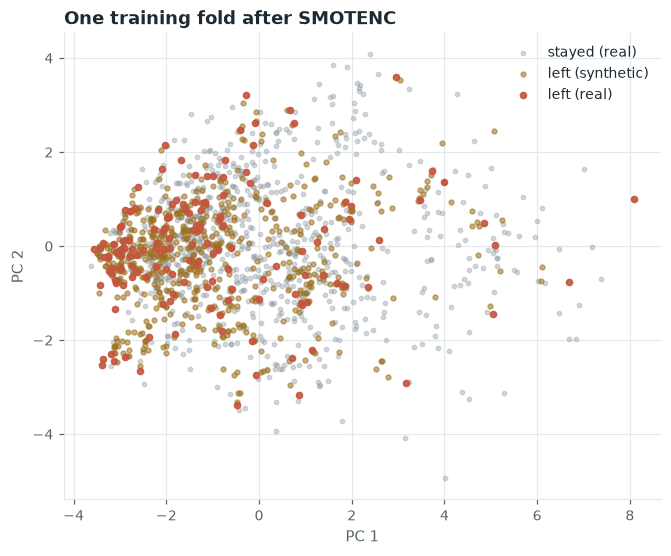

fold before: [788 152] | after: [788 788] | validation fold (untouched): [198  38]


In [4]:
from sklearn.decomposition import PCA
pipe = build_pipeline("logreg", "smotenc", 42, y_train)
fold_tr, fold_va = next(StratifiedKFold(5, shuffle=True, random_state=42).split(X_train, y_train))
Xf, yf = X_train.iloc[fold_tr], y_train.iloc[fold_tr]
Xi = pipe.named_steps["impute"].fit_transform(Xf)
Xr, yr = pipe.named_steps["sampler"].fit_resample(Xi, yf)
enc = pipe.named_steps["encode"].fit(Xi)
Zr = enc.transform(Xr)
pca = PCA(2, random_state=0).fit(enc.transform(Xi))
P = pca.transform(Zr); n = len(Xi); yr = np.asarray(yr)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(*P[:n][yr[:n] == 0].T, s=8, color=F.NEUTRAL, alpha=0.35, label="stayed (real)")
ax.scatter(*P[n:].T, s=10, color=F.AMBER, alpha=0.55, label="left (synthetic)")
ax.scatter(*P[:n][yr[:n] == 1].T, s=16, color=F.CLAY, alpha=0.9, label="left (real)")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(); ax.set_title("One training fold after SMOTENC"); plt.show()
print("fold before:", np.bincount(yf), "| after:", np.bincount(yr), "| validation fold (untouched):", np.bincount(y_train.iloc[fold_va]))

Synthetic leavers fill the space *between* real leavers. In this dataset leavers overlap heavily with stayers, so the
synthetic points also land inside the stayers' region. The boundary moves towards the stayers (more leavers flagged),
but the ordering of real employees improves little.

## 3. The controlled comparison (default experiment)

Each of six algorithms was tuned and evaluated under four strategies with identical folds, seeds and search budgets.
The numbers are mean PR-AUC over 15 cross-validation folds on the training set.

In [5]:
cv_sum = b.cv_summary
piv = cv_sum.pivot_table(index="model_name", columns="strategy_name", values="cv_pr_auc_mean")
piv = piv[["No rebalancing", "Class weights", "SMOTENC", "Random oversampling"]].sort_values("No rebalancing", ascending=False)
piv.style.format("{:.3f}").background_gradient(cmap="Greens", axis=None)

strategy_name,No rebalancing,Class weights,SMOTENC,Random oversampling
model_name,,,,
Logistic regression,0.662,0.635,0.576,0.625
Support vector machine,0.657,0.651,0.568,0.637
XGBoost,0.640,0.632,0.560,0.617
LightGBM,0.624,0.619,0.551,0.598
Random forest,0.557,0.557,0.529,0.546
Decision tree,0.360,0.351,0.365,0.360
Dummy (prior),0.162,nan,nan,nan


In [6]:
base = cv_sum[cv_sum.strategy == "none"].set_index("model")
rows = []
for _, r in cv_sum[cv_sum.strategy != "none"].iterrows():
    b0 = base.loc[r["model"]]
    se = np.sqrt((r["cv_pr_auc_std"] ** 2 + b0["cv_pr_auc_std"] ** 2) / r["n_folds"])
    rows.append({"algorithm": r["model_name"], "strategy": r["strategy_name"],
                 "Δ PR-AUC": r["cv_pr_auc_mean"] - b0["cv_pr_auc_mean"], "≈2 SE": 2 * se,
                 "Δ recall@0.5": r["cv_recall_mean"] - b0["cv_recall_mean"],
                 "Δ Brier": r["cv_brier_mean"] - b0["cv_brier_mean"]})
delta = pd.DataFrame(rows)
delta.sort_values(["strategy", "Δ PR-AUC"])

,algorithm,strategy,Δ PR-AUC,≈2 SE,Δ recall@0.5,Δ Brier
2,Logistic regression,Class weights,-2.709e-02,0.046,0.335,0.065
17,Decision tree,Class weights,-9.078e-03,0.046,0.242,0.072
3,XGBoost,Class weights,-7.534e-03,0.046,0.307,0.034
0,Support vector machine,Class weights,-5.353e-03,0.051,-0.067,0.003
5,LightGBM,Class weights,-4.559e-03,0.050,0.342,0.041
11,Random forest,Class weights,-9.000e-05,0.057,0.365,0.033
4,Logistic regression,Random oversampling,-3.721e-02,0.047,0.342,0.068
7,LightGBM,Random oversampling,-2.548e-02,0.051,0.316,0.040
6,XGBoost,Random oversampling,-2.269e-02,0.048,0.291,0.036
1,Support vector machine,Random oversampling,-1.980e-02,0.051,0.291,0.057


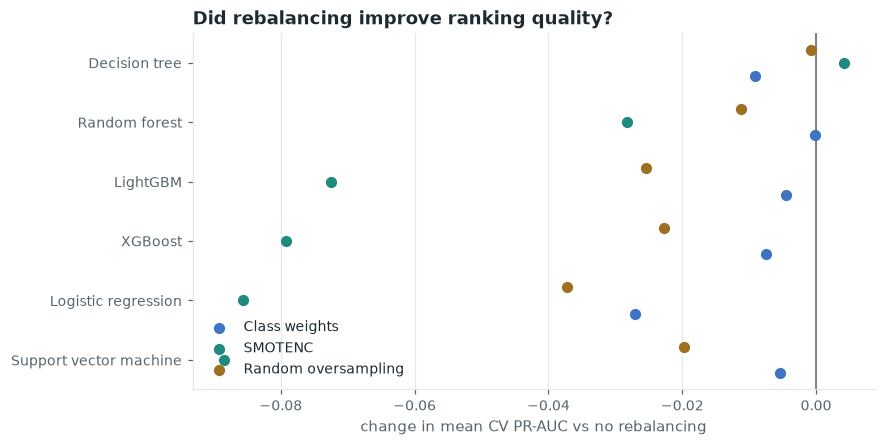

SMOTENC improved PR-AUC for 1 of 6 algorithms; median change -0.076. It raised recall at 0.5 for 6 of 6.


In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
strategies = ["Class weights", "SMOTENC", "Random oversampling"]
colors = [F.BLUE, F.TEAL, F.AMBER]
algos = delta["algorithm"].unique()
for i, (s, c) in enumerate(zip(strategies, colors)):
    d = delta[delta.strategy == s].set_index("algorithm").reindex(algos)
    ax.scatter(d["Δ PR-AUC"], np.arange(len(algos)) + (i - 1) * 0.22, color=c, s=40, label=s, zorder=3)
ax.axvline(0, color=F.MUTED, lw=1)
ax.set_yticks(range(len(algos)), algos); ax.set_xlabel("change in mean CV PR-AUC vs no rebalancing")
ax.legend(loc="lower left"); ax.set_title("Did rebalancing improve ranking quality?"); ax.grid(axis="y", visible=False); plt.show()
sm = delta[delta.strategy == "SMOTENC"]
print(f"SMOTENC improved PR-AUC for {(sm['Δ PR-AUC'] > 0).sum()} of {len(sm)} algorithms; "
      f"median change {sm['Δ PR-AUC'].median():+.3f}. It raised recall at 0.5 for {(sm['Δ recall@0.5'] > 0).sum()} of {len(sm)}.")

**Findings (from the saved artefacts above)**

1. **SMOTENC lowered mean CV PR-AUC for five of six algorithms**, four of them by more than two standard errors. The
   exception, the single decision tree, moved by +0.004, which is noise.
2. **Class weights** and **random oversampling** were close to neutral for most algorithms. They were sometimes
   marginally lower and rarely higher, and the differences sat inside fold-to-fold noise.
3. All three strategies raise **recall at the 0.5 threshold** and worsen the **Brier score**. They shift predicted
   probabilities up, much as lowering the threshold would, without that step's transparency.
4. The best configuration overall used **no rebalancing**, with a threshold tuned on out-of-fold predictions (notebook
   06). That gives the recall benefit while keeping probabilities calibrated.

Why might SMOTENC hurt here? With about 150 leavers per training fold and 51 one-hot inputs, the nearest leaver
neighbours are often far apart. Interpolating between them creates implausible employees in regions dominated by
stayers, which adds label noise near the boundary.

## 4. Sensitivity of SMOTENC to its settings

Is the negative result just a bad configuration? The check below runs a small grid over the sampling ratio and *k* for
logistic regression, with fixed C, using the same CV folds.

In [8]:
from sklearn.model_selection import cross_val_score
cv5 = StratifiedKFold(5, shuffle=True, random_state=7)
C = b.best_params["logreg|none"]["C"]
ref = cross_val_score(build_pipeline("logreg", "none", 42, y_train).set_params(model__C=C), X_train, y_train,
                      cv=cv5, scoring="average_precision").mean()
grid = []
for ratio in (0.35, 0.5, 0.75, 1.0):
    for k in (3, 5, 10):
        p = build_pipeline("logreg", "smotenc", 42, y_train, smote_sampling_strategy=ratio, smote_k_neighbors=k).set_params(model__C=C)
        grid.append({"ratio": ratio, "k": k, "PR-AUC": cross_val_score(p, X_train, y_train, cv=cv5, scoring="average_precision").mean()})
g = pd.DataFrame(grid).pivot(index="ratio", columns="k", values="PR-AUC")
print(f"no rebalancing (same C, same folds): {ref:.3f}")
g.style.format("{:.3f}")

no rebalancing (same C, same folds): 0.661


k,3,5,10
ratio,,,
0.350000,0.644,0.630,0.627
0.500000,0.628,0.610,0.596
0.750000,0.610,0.598,0.568
1.000000,0.607,0.581,0.555


In [9]:
print(f"best SMOTENC setting: {g.max().max():.3f} vs {ref:.3f} without rebalancing "
      f"({g.max().max() - ref:+.3f}). Milder ratios hurt less, but none beat the baseline here.")

best SMOTENC setting: 0.644 vs 0.661 without rebalancing (-0.017). Milder ratios hurt less, but none beat the baseline here.


The pattern holds across settings. Gentler oversampling (a lower ratio) does less damage, but no configuration in the
grid clearly beats no rebalancing. SMOTENC stays available in the Model laboratory so the comparison can be repeated.

## Summary

| Strategy | Effect on PR-AUC (ranking) | Effect at 0.5 threshold | Calibration |
|---|---|---|---|
| None + tuned threshold | best overall | threshold chosen on OOF data | best |
| Class weights | about neutral | recall up, precision down | worse |
| Random oversampling | neutral to slightly lower | recall up | worse |
| SMOTENC | lower for 5 of 6 algorithms; no meaningful gain anywhere | recall up | worse |

Resampling only ever touched training folds; the evidence is in `experiments/default/resampling.json`.